# 01 — Exploration des données Olist

**Projet :** Olist Brazilian E-Commerce Public Dataset  
**Responsable :** Personne 1 — Semaine 1  
**Objectif :** comprendre la structure, la qualité et les relations potentielles des neuf fichiers CSV avant toute opération de nettoyage.

> Important : ce notebook est consacré à l'observation. Il ne supprime pas les doublons, ne remplace pas les valeurs manquantes et ne modifie pas les fichiers originaux.

## 1. Questions de l'exploration

- Quels fichiers sont disponibles et quelles sont leurs dimensions ?
- Quels sont les types de colonnes et les principales distributions ?
- Où se trouvent les valeurs manquantes et les doublons complets ?
- Quelles clés peuvent relier les tables ?
- Quelles anomalies faudra-t-il examiner pendant l'étape de nettoyage ?

In [1]:
from pathlib import Path
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 160)

sns.set_theme(style="whitegrid", context="notebook")
print("pandas :", pd.__version__)
print("numpy :", np.__version__)
print("Répertoire de travail :", Path.cwd())

pandas : 2.2.3
numpy : 2.1.3
Répertoire de travail : c:\Users\PC\OneDrive\Desktop\olist-data-engineerin\notebooks


## 2. Configuration des chemins

Le notebook cherche le dossier `data/raw` depuis le répertoire courant et ses dossiers parents. Si le projet est organisé différemment, adapte `PROJECT_ROOT` manuellement dans la cellule ci-dessous.

In [2]:
def trouver_racine_projet(start: Path) -> Path:
    """Cherche une racine de projet contenant data/raw, en remontant les parents."""
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "data" / "raw").is_dir():
            return candidate
    raise FileNotFoundError(
        "Impossible de trouver data/raw depuis le répertoire courant. "
        "Ouvre VS Code à la racine du projet ou définis PROJECT_ROOT manuellement."
    )

PROJECT_ROOT = trouver_racine_projet(Path.cwd())
DATA_DIR = PROJECT_ROOT / "data" / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
RESULTS_DIR = REPORTS_DIR / "results"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Racine du projet :", PROJECT_ROOT)
print("Dossier des données :", DATA_DIR)
print("Dossier des figures :", FIGURES_DIR)
print("Dossier des résultats :", RESULTS_DIR)

Racine du projet : C:\Users\PC\OneDrive\Desktop\olist-data-engineerin
Dossier des données : C:\Users\PC\OneDrive\Desktop\olist-data-engineerin\data\raw
Dossier des figures : C:\Users\PC\OneDrive\Desktop\olist-data-engineerin\reports\figures
Dossier des résultats : C:\Users\PC\OneDrive\Desktop\olist-data-engineerin\reports\results


## 3. Vérification des fichiers attendus

Le dataset Olist contient normalement les neuf fichiers listés ci-dessous. Le notebook signale les fichiers absents et les CSV supplémentaires, sans arrêter toute l'analyse si un fichier manque.

In [3]:
FICHIERS_ATTENDUS = [
    "olist_customers_dataset.csv",
    "olist_geolocation_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_orders_dataset.csv",
    "olist_products_dataset.csv",
    "olist_sellers_dataset.csv",
    "product_category_name_translation.csv",
]

fichiers_csv = sorted(DATA_DIR.glob("*.csv"))
noms_disponibles = {f.name for f in fichiers_csv}
manquants = [nom for nom in FICHIERS_ATTENDUS if nom not in noms_disponibles]
supplementaires = [f.name for f in fichiers_csv if f.name not in FICHIERS_ATTENDUS]

inventaire = pd.DataFrame([
    {
        "fichier": f.name,
        "taille_Mo": round(f.stat().st_size / (1024 ** 2), 2),
        "attendu": f.name in FICHIERS_ATTENDUS
    }
    for f in fichiers_csv
])

display(inventaire)
print(f"Nombre de CSV trouvés : {len(fichiers_csv)}")
print("Fichiers attendus manquants :", manquants if manquants else "Aucun")
print("Fichiers CSV supplémentaires :", supplementaires if supplementaires else "Aucun")

if not fichiers_csv:
    raise FileNotFoundError(f"Aucun fichier CSV trouvé dans : {DATA_DIR}")

,fichier,taille_Mo,attendu
0,olist_customers_dataset.csv,8.62,True
1,olist_geolocation_dataset.csv,58.44,True
2,olist_order_items_dataset.csv,14.72,True
3,olist_order_payments_dataset.csv,5.51,True
4,olist_order_reviews_dataset.csv,13.78,True
5,olist_orders_dataset.csv,16.84,True
6,olist_products_dataset.csv,2.27,True
7,olist_sellers_dataset.csv,0.17,True
8,product_category_name_translation.csv,0.00,True


Nombre de CSV trouvés : 9
Fichiers attendus manquants : Aucun
Fichiers CSV supplémentaires : Aucun


## 4. Chargement contrôlé des CSV

Les fichiers sont chargés une seule fois dans le dictionnaire `tables`. Le chargement utilise l'encodage UTF-8 par défaut. Si un fichier présente une erreur d'encodage, le notebook affiche le problème explicitement au lieu de changer silencieusement l'encodage.

In [4]:
tables = {}
erreurs_chargement = []

for fichier in fichiers_csv:
    nom_table = fichier.stem.replace("_dataset", "")
    try:
        tables[nom_table] = pd.read_csv(fichier, encoding="utf-8", low_memory=False)
        print(f"OK  {fichier.name}: {tables[nom_table].shape[0]:,} lignes × {tables[nom_table].shape[1]} colonnes")
    except UnicodeDecodeError as exc:
        erreurs_chargement.append({
            "fichier": fichier.name,
            "erreur": "Erreur d'encodage UTF-8",
            "detail": str(exc)
        })
        print(f"ERREUR D'ENCODAGE — {fichier.name}: {exc}")
    except Exception as exc:
        erreurs_chargement.append({
            "fichier": fichier.name,
            "erreur": type(exc).__name__,
            "detail": str(exc)
        })
        print(f"ERREUR — {fichier.name}: {type(exc).__name__}: {exc}")

if erreurs_chargement:
    display(pd.DataFrame(erreurs_chargement))

OK  olist_customers_dataset.csv: 99,441 lignes × 5 colonnes
OK  olist_geolocation_dataset.csv: 1,000,163 lignes × 5 colonnes
OK  olist_order_items_dataset.csv: 112,650 lignes × 7 colonnes
OK  olist_order_payments_dataset.csv: 103,886 lignes × 5 colonnes
OK  olist_order_reviews_dataset.csv: 99,224 lignes × 7 colonnes
OK  olist_orders_dataset.csv: 99,441 lignes × 8 colonnes
OK  olist_products_dataset.csv: 32,951 lignes × 9 colonnes
OK  olist_sellers_dataset.csv: 3,095 lignes × 4 colonnes
OK  product_category_name_translation.csv: 71 lignes × 2 colonnes


## 5. Dimensions et types de données

Cette section résume le nombre de lignes et de colonnes, la mémoire approximative utilisée et les types de variables. Les identifiants sont conservés comme identifiants : ils ne sont pas interprétés comme des mesures quantitatives.

In [5]:
lignes_dimensions = []
lignes_types = []

for nom, df in tables.items():
    lignes_dimensions.append({
        "table": nom,
        "lignes": len(df),
        "colonnes": df.shape[1],
        "memoire_Mo": round(df.memory_usage(deep=True).sum() / (1024 ** 2), 2),
        "colonnes_numeriques": int(df.select_dtypes(include=np.number).shape[1]),
        "colonnes_objet_ou_texte": int(df.select_dtypes(include=["object", "string"]).shape[1]),
        "colonnes_datetime": int(df.select_dtypes(include=["datetime", "datetimetz"]).shape[1]),
    })
    for col in df.columns:
        lignes_types.append({
            "table": nom,
            "colonne": col,
            "type": str(df[col].dtype),
            "valeurs_distinctes": int(df[col].nunique(dropna=True)),
        })

dimensions = pd.DataFrame(lignes_dimensions).sort_values("table")
types_colonnes = pd.DataFrame(lignes_types)

display(dimensions)
display(types_colonnes)
dimensions.to_csv(RESULTS_DIR / "exploration_dimensions.csv", index=False)
types_colonnes.to_csv(RESULTS_DIR / "exploration_types_colonnes.csv", index=False)

,table,lignes,colonnes,memoire_Mo,colonnes_numeriques,colonnes_objet_ou_texte,colonnes_datetime
0,olist_customers,99441,5,26.59,1,4,0
1,olist_geolocation,1000163,5,129.38,3,2,0
2,olist_order_items,112650,7,35.99,3,4,0
3,olist_order_payments,103886,5,16.23,3,2,0
4,olist_order_reviews,99224,7,39.12,1,6,0
5,olist_orders,99441,8,52.94,0,8,0
6,olist_products,32951,9,6.30,7,2,0
7,olist_sellers,3095,4,0.59,1,3,0
8,product_category_name_translation,71,2,0.01,0,2,0


,table,colonne,type,valeurs_distinctes
0,olist_customers,customer_id,object,99441
1,olist_customers,customer_unique_id,object,96096
2,olist_customers,customer_zip_code_prefix,int64,14994
3,olist_customers,customer_city,object,4119
4,olist_customers,customer_state,object,27
5,olist_geolocation,geolocation_zip_code_prefix,int64,19015
6,olist_geolocation,geolocation_lat,float64,717360
7,olist_geolocation,geolocation_lng,float64,717613
8,olist_geolocation,geolocation_city,object,8011
9,olist_geolocation,geolocation_state,object,27


## 6. Aperçu des tables

Les premières lignes permettent de vérifier les noms de colonnes et le format général des données.

In [6]:
for nom, df in tables.items():
    print(f"### {nom} — aperçu")
    display(df.head(5))

### olist_customers — aperçu


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


### olist_geolocation — aperçu


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


### olist_order_items — aperçu


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


... (8 outputs left out)

### olist_sellers — aperçu


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


### product_category_name_translation — aperçu


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


## 7. Valeurs manquantes

Les valeurs manquantes sont calculées par colonne et par table. Elles sont documentées ici, mais ne sont pas corrigées dans cette étape.

In [7]:
missing_rows = []
for nom, df in tables.items():
    for col in df.columns:
        nb = int(df[col].isna().sum())
        missing_rows.append({
            "table": nom,
            "colonne": col,
            "valeurs_manquantes": nb,
            "pourcentage_manquant": round(100 * nb / len(df), 2) if len(df) else 0.0
        })

missing = pd.DataFrame(missing_rows)
missing = missing.sort_values(["pourcentage_manquant", "valeurs_manquantes"], ascending=False)
display(missing[missing["valeurs_manquantes"] > 0].reset_index(drop=True))
missing.to_csv(RESULTS_DIR / "exploration_missing_values.csv", index=False)

missing_par_table = pd.DataFrame([
    {
        "table": nom,
        "lignes_avec_au_moins_une_valeur_manquante": int(df.isna().any(axis=1).sum()),
        "pourcentage_lignes_concernees": round(100 * df.isna().any(axis=1).mean(), 2) if len(df) else 0.0
    }
    for nom, df in tables.items()
])
display(missing_par_table)

,table,colonne,valeurs_manquantes,pourcentage_manquant
0,olist_order_reviews,review_comment_title,87656,88.34
1,olist_order_reviews,review_comment_message,58247,58.70
2,olist_orders,order_delivered_customer_date,2965,2.98
3,olist_products,product_category_name,610,1.85
4,olist_products,product_name_lenght,610,1.85
5,olist_products,product_description_lenght,610,1.85
6,olist_products,product_photos_qty,610,1.85
7,olist_orders,order_delivered_carrier_date,1783,1.79
8,olist_orders,order_approved_at,160,0.16
9,olist_products,product_weight_g,2,0.01


,table,lignes_avec_au_moins_une_valeur_manquante,pourcentage_lignes_concernees
0,olist_customers,0,0.00
1,olist_geolocation,0,0.00
2,olist_order_items,0,0.00
3,olist_order_payments,0,0.00
4,olist_order_reviews,89385,90.08
5,olist_orders,2980,3.00
6,olist_products,611,1.85
7,olist_sellers,0,0.00
8,product_category_name_translation,0,0.00


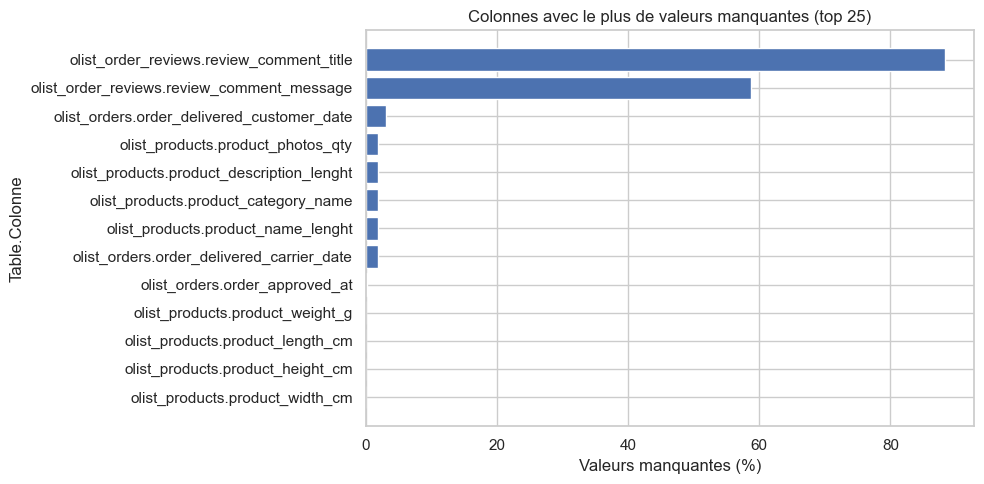

In [8]:
missing_plot = missing[missing["valeurs_manquantes"] > 0].copy()
if not missing_plot.empty:
    missing_plot["variable"] = missing_plot["table"] + "." + missing_plot["colonne"]
    missing_plot = missing_plot.sort_values("pourcentage_manquant", ascending=True).tail(25)
    plt.figure(figsize=(10, max(5, len(missing_plot) * 0.28)))
    plt.barh(missing_plot["variable"], missing_plot["pourcentage_manquant"])
    plt.xlabel("Valeurs manquantes (%)")
    plt.ylabel("Table.Colonne")
    plt.title("Colonnes avec le plus de valeurs manquantes (top 25)")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "valeurs_manquantes_top25.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Aucune valeur manquante détectée dans les tables chargées.")

## 8. Doublons complets

Un doublon complet signifie que toutes les valeurs d'une ligne sont identiques à celles d'une autre ligne. Ce contrôle est différent de la répétition d'un identifiant, qui peut être normale dans une table de détail comme les articles d'une commande.

In [9]:
doublons_rows = []
for nom, df in tables.items():
    nb = int(df.duplicated().sum())
    doublons_rows.append({
        "table": nom,
        "doublons_complets": nb,
        "pourcentage_doublons": round(100 * nb / len(df), 3) if len(df) else 0.0
    })

doublons = pd.DataFrame(doublons_rows).sort_values("doublons_complets", ascending=False)
display(doublons)
doublons.to_csv(RESULTS_DIR / "exploration_duplicates.csv", index=False)

,table,doublons_complets,pourcentage_doublons
1,olist_geolocation,261831,26.179
0,olist_customers,0,0.000
2,olist_order_items,0,0.000
3,olist_order_payments,0,0.000
4,olist_order_reviews,0,0.000
5,olist_orders,0,0.000
6,olist_products,0,0.000
7,olist_sellers,0,0.000
8,product_category_name_translation,0,0.000


## 9. Statistiques descriptives préliminaires

Les statistiques sont calculées pour les colonnes numériques. Certaines colonnes numériques peuvent être des identifiants ou des codes : leurs moyennes et écarts-types ne doivent pas être interprétés comme des mesures métier.

In [10]:
for nom, df in tables.items():
    numeriques = df.select_dtypes(include=np.number)
    print(f"### {nom}")
    if numeriques.empty:
        print("Aucune colonne numérique détectée.")
    else:
        display(numeriques.describe().T)

### olist_customers


,count,mean,std,min,25%,50%,75%,max
customer_zip_code_prefix,99441.0,35137.474583,29797.938996,1003.0,11347.0,24416.0,58900.0,99990.0


### olist_geolocation


,count,mean,std,min,25%,50%,75%,max
geolocation_zip_code_prefix,1000163.0,36574.166466,30549.335710,1001.000000,11075.000000,26530.000000,63504.000000,99990.000000
geolocation_lat,1000163.0,-21.176153,5.715866,-36.605374,-23.603546,-22.919377,-19.979620,45.065933
geolocation_lng,1000163.0,-46.390541,4.269748,-101.466766,-48.573172,-46.637879,-43.767709,121.105394


### olist_order_items


,count,mean,std,min,25%,50%,75%,max
order_item_id,112650.0,1.197834,0.705124,1.00,1.00,1.00,1.00,21.00
price,112650.0,120.653739,183.633928,0.85,39.90,74.99,134.90,6735.00
freight_value,112650.0,19.990320,15.806405,0.00,13.08,16.26,21.15,409.68


... (5 outputs left out)

,count,mean,std,min,25%,50%,75%,max
product_name_lenght,32341.0,48.476949,10.245741,5.0,42.0,51.0,57.0,76.0
product_description_lenght,32341.0,771.495285,635.115225,4.0,339.0,595.0,972.0,3992.0
product_photos_qty,32341.0,2.188986,1.736766,1.0,1.0,1.0,3.0,20.0
product_weight_g,32949.0,2276.472488,4282.038731,0.0,300.0,700.0,1900.0,40425.0
product_length_cm,32949.0,30.815078,16.914458,7.0,18.0,25.0,38.0,105.0
product_height_cm,32949.0,16.937661,13.637554,2.0,8.0,13.0,21.0,105.0
product_width_cm,32949.0,23.196728,12.079047,6.0,15.0,20.0,30.0,118.0


### olist_sellers


,count,mean,std,min,25%,50%,75%,max
seller_zip_code_prefix,3095.0,32291.059451,32713.45383,1001.0,7093.5,14940.0,64552.5,99730.0


### product_category_name_translation
Aucune colonne numérique détectée.


## 10. Distributions de variables métier

Le notebook tente de tracer des distributions pour des variables numériques métier courantes lorsqu'elles existent. Les graphiques ne sont générés que si les colonnes sont présentes.

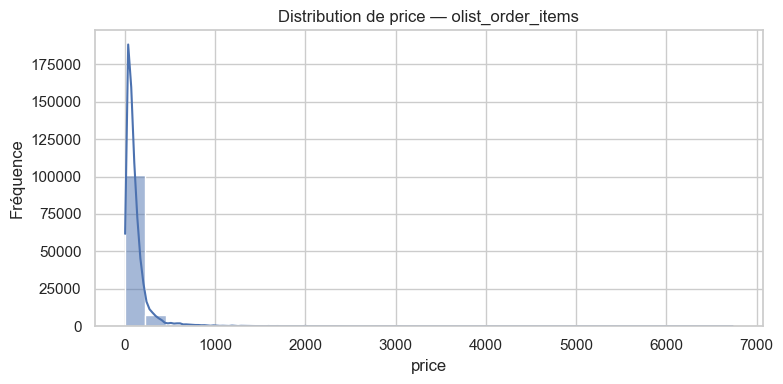

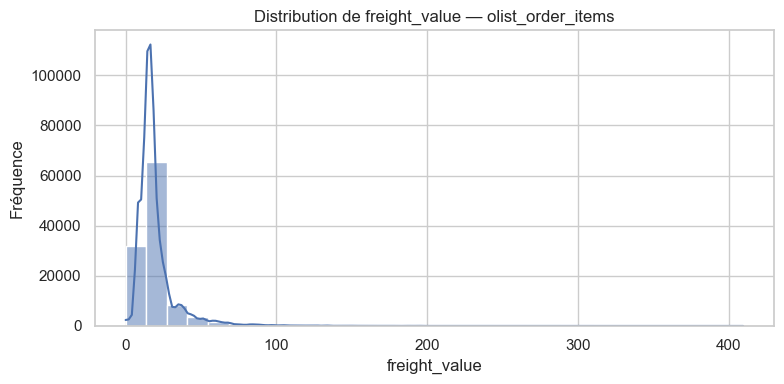

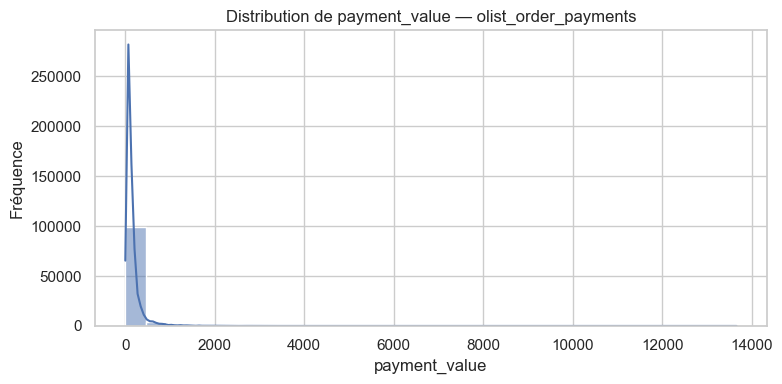

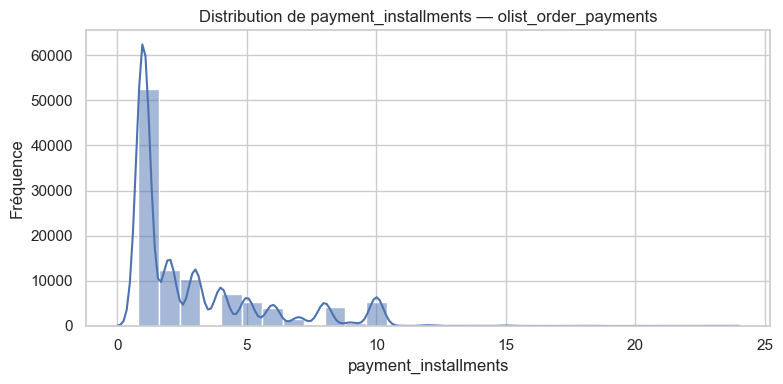

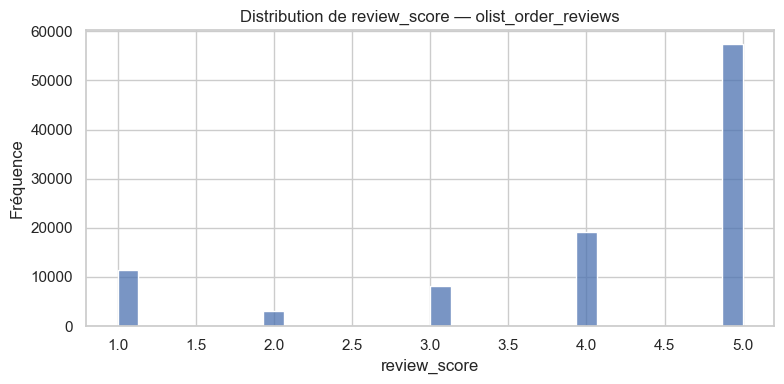

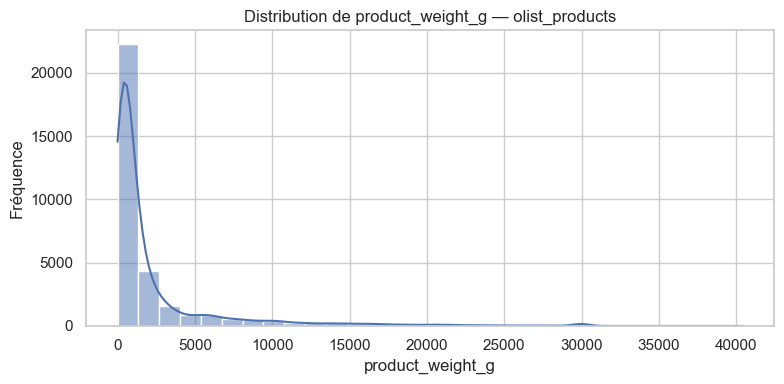

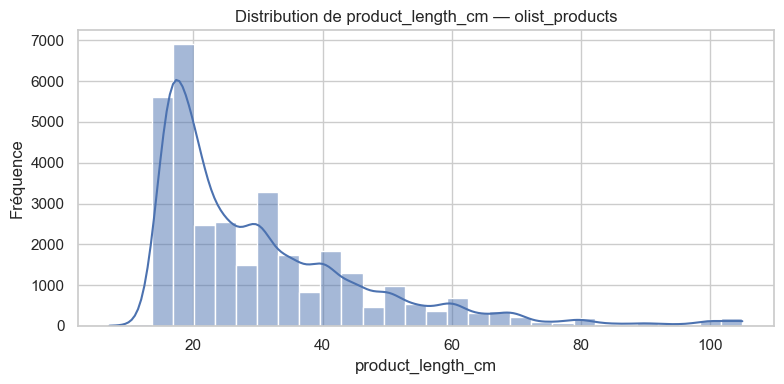

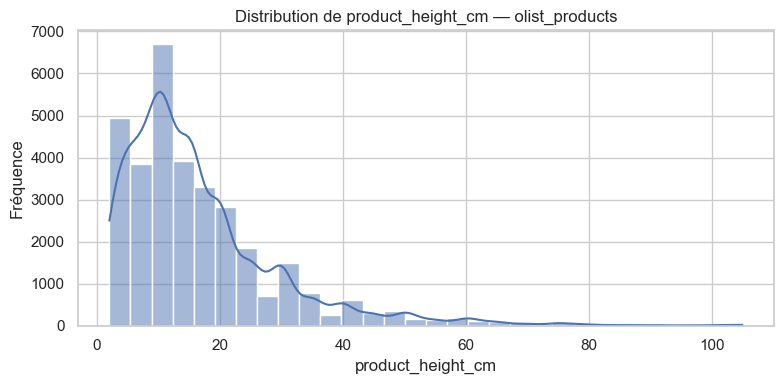

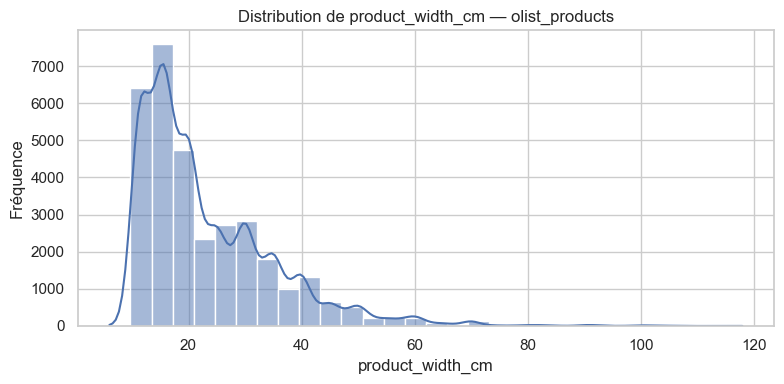

In [11]:

variables_metier = {
    "olist_order_items": ["price", "freight_value"],
    "olist_order_payments": ["payment_value", "payment_installments"],
    "olist_order_reviews": ["review_score"],
    "olist_products": [
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm"
    ],
}


for nom_table, colonnes in variables_metier.items():
    df = tables.get(nom_table)
    if df is None:
        continue
    for col in colonnes:
        if col in df.columns and pd.api.types.is_numeric_dtype(df[col]):
            serie = df[col].dropna()
            if serie.empty:
                continue
            plt.figure(figsize=(8, 4))
            sns.histplot(serie, bins=30, kde=(serie.nunique() > 10))
            plt.title(f"Distribution de {col} — {nom_table}")
            plt.xlabel(col)
            plt.ylabel("Fréquence")
            plt.tight_layout()
            nom_fichier = f"distribution_{nom_table}_{col}.png"
            plt.savefig(FIGURES_DIR / nom_fichier, dpi=150, bbox_inches="tight")
            plt.show()

In [12]:
print("Tables disponibles :")
print(list(tables.keys()))

for nom_table, df in tables.items():
    print(f"\n--- {nom_table} ---")
    print("Dimensions :", df.shape)
    print("Colonnes :", df.columns.tolist())
    print(df.dtypes)

Tables disponibles :
['olist_customers', 'olist_geolocation', 'olist_order_items', 'olist_order_payments', 'olist_order_reviews', 'olist_orders', 'olist_products', 'olist_sellers', 'product_category_name_translation']

--- olist_customers ---
Dimensions : (99441, 5)
Colonnes : ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

--- olist_geolocation ---
Dimensions : (1000163, 5)
Colonnes : ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                object
geolocation_state               object
dtype: object

--- olist_order_items ---
Dimensions : (112650,

## 11. Vérification des clés candidates

Les contrôles ci-dessous vérifient les identifiants candidats s'ils existent dans les tables chargées. Une répétition n'est pas automatiquement une erreur : par exemple, `order_id` peut apparaître plusieurs fois dans la table des articles d'une commande.

In [13]:

cles_candidates = {
    "olist_customers": ["customer_id", "customer_unique_id"],
    "olist_orders": ["order_id", "customer_id"],
    "olist_order_items": ["order_id", "order_item_id", "product_id", "seller_id"],
    "olist_order_payments": ["order_id"],
    "olist_order_reviews": ["review_id", "order_id"],
    "olist_products": ["product_id"],
    "olist_sellers": ["seller_id"],
    "olist_geolocation": ["geolocation_zip_code_prefix"],
    "product_category_name_translation": ["product_category_name"],
}

cles_rows = []

for nom_table, cles_table in cles_candidates.items():
    df = tables.get(nom_table)

    if df is None:
        print(f"Table absente du dictionnaire : {nom_table}")
        continue

    for col in cles_table:
        if col in df.columns:
            cles_rows.append({
                "table": nom_table,
                "colonne": col,
                "valeurs_manquantes": int(df[col].isna().sum()),
                "valeurs_distinctes": int(df[col].nunique(dropna=True)),
                "lignes": len(df),
                "unique_sur_lignes_non_nulles": bool(
                    df[col].dropna().is_unique
                ),
                "doublons_non_nulls": int(
                    df[col].dropna().duplicated().sum()
                )
            })
        else:
            print(f"Colonne absente : {nom_table}.{col}")

cles_df = pd.DataFrame(cles_rows)

display(cles_df)

cles_df.to_csv(
    RESULTS_DIR / "exploration_keys.csv",
    index=False
)


,table,colonne,valeurs_manquantes,valeurs_distinctes,lignes,unique_sur_lignes_non_nulles,doublons_non_nulls
0,olist_customers,customer_id,0,99441,99441,True,0
1,olist_customers,customer_unique_id,0,96096,99441,False,3345
2,olist_orders,order_id,0,99441,99441,True,0
3,olist_orders,customer_id,0,99441,99441,True,0
4,olist_order_items,order_id,0,98666,112650,False,13984
5,olist_order_items,order_item_id,0,21,112650,False,112629
6,olist_order_items,product_id,0,32951,112650,False,79699
7,olist_order_items,seller_id,0,3095,112650,False,109555
8,olist_order_payments,order_id,0,99440,103886,False,4446
9,olist_order_reviews,review_id,0,98410,99224,False,814


## 12. Vérification préliminaire de relations entre tables

Les vérifications suivantes sont des contrôles simples de références orphelines. Elles ne construisent pas de table fusionnée et ne remplacent pas la validation du modèle de données.

In [14]:

relations = [
    ("olist_orders", "customer_id", "olist_customers", "customer_id"),
    ("olist_order_items", "order_id", "olist_orders", "order_id"),
    ("olist_order_items", "product_id", "olist_products", "product_id"),
    ("olist_order_items", "seller_id", "olist_sellers", "seller_id"),
    ("olist_order_payments", "order_id", "olist_orders", "order_id"),
    ("olist_order_reviews", "order_id", "olist_orders", "order_id"),
]

relations_rows = []

for table_source, col_source, table_cible, col_cible in relations:
    src = tables.get(table_source)
    dst = tables.get(table_cible)

    if (
        src is None or dst is None
        or col_source not in src.columns
        or col_cible not in dst.columns
    ):
        relations_rows.append({
            "table_source": table_source,
            "colonne_source": col_source,
            "table_cible": table_cible,
            "colonne_cible": col_cible,
            "statut": "Non vérifiée : table ou colonne absente",
            "references_sans_correspondance": np.nan
        })
        continue

    valeurs_cibles = set(dst[col_cible].dropna().unique())
    source_non_null = src[col_source].dropna()

    orphelines = int(
        (~source_non_null.isin(valeurs_cibles)).sum()
    )

    relations_rows.append({
        "table_source": table_source,
        "colonne_source": col_source,
        "table_cible": table_cible,
        "colonne_cible": col_cible,
        "statut": "Vérifiée",
        "references_sans_correspondance": orphelines
    })

relations_df = pd.DataFrame(relations_rows)

display(relations_df)

relations_df.to_csv(
    RESULTS_DIR / "exploration_relations.csv",
    index=False
)


,table_source,colonne_source,table_cible,colonne_cible,statut,references_sans_correspondance
0,olist_orders,customer_id,olist_customers,customer_id,Vérifiée,0
1,olist_order_items,order_id,olist_orders,order_id,Vérifiée,0
2,olist_order_items,product_id,olist_products,product_id,Vérifiée,0
3,olist_order_items,seller_id,olist_sellers,seller_id,Vérifiée,0
4,olist_order_payments,order_id,olist_orders,order_id,Vérifiée,0
5,olist_order_reviews,order_id,olist_orders,order_id,Vérifiée,0


## 13. Couverture temporelle préliminaire

Les dates sont converties uniquement dans des séries de travail, sans modifier les DataFrames chargés. Les dates invalides sont comptées comme `NaT` et signalées.

In [15]:

colonnes_dates = {
    "olist_orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ],
    "olist_order_reviews": [
        "review_creation_date",
        "review_answer_timestamp",
    ],
}

dates_rows = []

for nom_table, colonnes in colonnes_dates.items():
    df = tables.get(nom_table)

    if df is None:
        print(f"Table introuvable : {nom_table}")
        continue

    for col in colonnes:
        if col not in df.columns:
            print(f"Colonne introuvable : {nom_table}.{col}")
            continue

        serie = pd.to_datetime(df[col], errors="coerce")

        dates_rows.append({
            "table": nom_table,
            "colonne": col,
            "dates_valides": int(serie.notna().sum()),
            "dates_invalides_ou_manquantes": int(serie.isna().sum()),
            "date_min": serie.min(),
            "date_max": serie.max(),
        })

dates_resume = pd.DataFrame(dates_rows)

display(dates_resume)

dates_resume.to_csv(
    RESULTS_DIR / "exploration_dates.csv",
    index=False
)

print("Résumé enregistré dans exploration_dates.csv")


,table,colonne,dates_valides,dates_invalides_ou_manquantes,date_min,date_max
0,olist_orders,order_purchase_timestamp,99441,0,2016-09-04 21:15:19,2018-10-17 17:30:18
1,olist_orders,order_approved_at,99281,160,2016-09-15 12:16:38,2018-09-03 17:40:06
2,olist_orders,order_delivered_carrier_date,97658,1783,2016-10-08 10:34:01,2018-09-11 19:48:28
3,olist_orders,order_delivered_customer_date,96476,2965,2016-10-11 13:46:32,2018-10-17 13:22:46
4,olist_orders,order_estimated_delivery_date,99441,0,2016-09-30 00:00:00,2018-11-12 00:00:00
5,olist_order_reviews,review_creation_date,99224,0,2016-10-02 00:00:00,2018-08-31 00:00:00
6,olist_order_reviews,review_answer_timestamp,99224,0,2016-10-07 18:32:28,2018-10-29 12:27:35


Résumé enregistré dans exploration_dates.csv


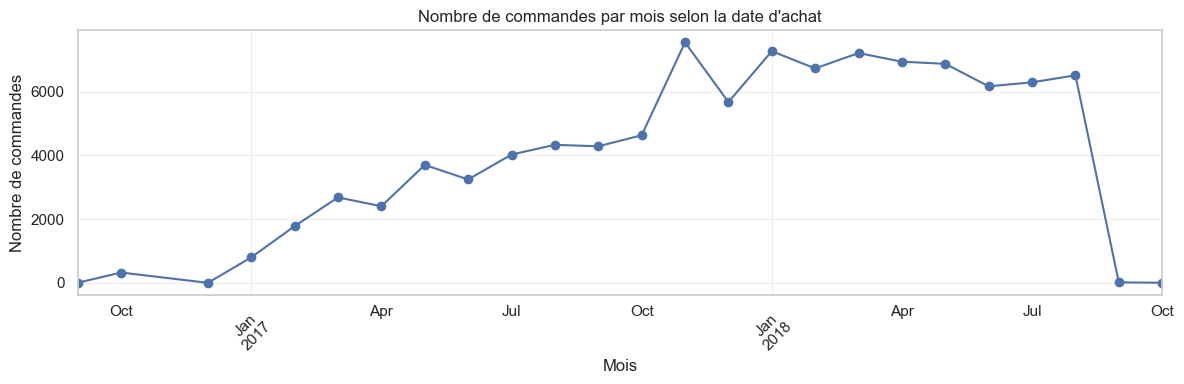

,nombre_commandes
order_purchase_timestamp,
2016-09,4
2016-10,324
2016-12,1
2017-01,800
2017-02,1780
2017-03,2682
2017-04,2404
2017-05,3700
2017-06,3245


Graphique enregistré : commandes_par_mois.png


In [16]:

df_orders = tables.get("olist_orders")

if df_orders is not None and "order_purchase_timestamp" in df_orders.columns:
    dates = pd.to_datetime(
        df_orders["order_purchase_timestamp"],
        errors="coerce"
    ).dropna()

    if not dates.empty:
        commandes_mensuelles = (
            dates.dt.to_period("M")
            .value_counts()
            .sort_index()
        )

        plt.figure(figsize=(12, 4))
        commandes_mensuelles.plot(
            kind="line",
            marker="o",
            linewidth=1.5
        )

        plt.title("Nombre de commandes par mois selon la date d'achat")
        plt.xlabel("Mois")
        plt.ylabel("Nombre de commandes")
        plt.xticks(rotation=45)
        plt.grid(True, alpha=0.3)
        plt.tight_layout()

        plt.savefig(
            FIGURES_DIR / "commandes_par_mois.png",
            dpi=150,
            bbox_inches="tight"
        )

        plt.show()

        display(
            commandes_mensuelles
            .rename("nombre_commandes")
            .to_frame()
        )

        print("Graphique enregistré : commandes_par_mois.png")

    else:
        print("Aucune date d'achat valide pour tracer la série temporelle.")

else:
    print("Table ou colonne de date d'achat absente : graphique ignoré.")


## 14. Synthèse automatique de l'exploration

La synthèse ci-dessous est construite à partir des résultats réellement calculés pendant l'exécution.

In [17]:

synthese = {
    "nombre_csv_trouves": int(len(fichiers_csv)),
    "nombre_tables_chargees": int(len(tables)),
    "tables_non_chargees": [
        e["fichier"] for e in erreurs_chargement
    ],
    "fichiers_attendus_manquants": manquants,
    "nombre_total_lignes": int(
        sum(len(df) for df in tables.values())
    ),
    "nombre_total_colonnes_table_par_table": {
        nom: int(df.shape[1])
        for nom, df in tables.items()
    },
    "tables_avec_doublons_complets": (
        doublons.loc[
            doublons["doublons_complets"] > 0,
            "table"
        ].tolist()
        if not doublons.empty else []
    ),
    "colonnes_avec_valeurs_manquantes": int(
        (missing["valeurs_manquantes"] > 0).sum()
    ),
}

print(json.dumps(synthese, ensure_ascii=False, indent=2))

with open(
    RESULTS_DIR / "exploration_synthese.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(synthese, f, ensure_ascii=False, indent=2)

print("Synthèse enregistrée dans exploration_synthese.json")


{
  "nombre_csv_trouves": 9,
  "nombre_tables_chargees": 9,
  "tables_non_chargees": [],
  "fichiers_attendus_manquants": [],
  "nombre_total_lignes": 1550922,
  "nombre_total_colonnes_table_par_table": {
    "olist_customers": 5,
    "olist_geolocation": 5,
    "olist_order_items": 7,
    "olist_order_payments": 5,
    "olist_order_reviews": 7,
    "olist_orders": 8,
    "olist_products": 9,
    "olist_sellers": 4,
    "product_category_name_translation": 2
  },
  "tables_avec_doublons_complets": [
    "olist_geolocation"
  ],
  "colonnes_avec_valeurs_manquantes": 13
}
Synthèse enregistrée dans exploration_synthese.json
